### 01 · PCA de la presión (dominio Mediterráneo occidental, 30–48 °N, 5 °W–20 °E)
30 PCs de presión a 6 h, 1940–2026, entrenadas en 1985–2015. Salida: `outputs/pca/pca_msl.pkl` y `outputs/pca/pcs_msl_30_6h.csv`.
El dominio completo (25–55 °N, 20 °W–40 °E) está archivado en `outputs/_archivo/pca/dominio_completo/`.

In [1]:
import os

import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from bluemath_tk.datamining import PCA
from sklearn.decomposition import PCA as PCA_

#### Load Data (6 h: 00/06/12/18)

In [2]:
era5 = xr.open_zarr('data/era5_mslp_grad_1985_2026_1deg_hourly.zarr').rename({'valid_time': 'time'})
era5 = era5.sel(time=era5.time.dt.hour.isin([0, 6, 12, 18]))
era5 = era5.sel(latitude=slice(48, 30), longitude=slice(-5, 20))                     # dominio: Mediterráneo occidental

training = slice('1985-01-01', '2015-12-31')

#### PCA de la presión (bluemath, solver de covarianza)

In [3]:
N_PCS = 30

pca_msl = PCA(n_components=N_PCS)
pca_msl._pca = PCA_(n_components=N_PCS, svd_solver='covariance_eigh')
pca_msl.fit_transform(data=era5[['msl']].sel(time=training), vars_to_stack=['msl'],
                      coords_to_stack=['latitude', 'longitude'], pca_dim_for_rows='time')

2026-11-26 16:39:28,623 - PCA - WARNING - Using PCA
2026-11-26 16:39:30,583 - PCA - WARNING - Using 450 out of 450 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method


<xarray.Dataset> Size: 6MB
Dimensions:      (time: 45288, n_component: 30)
Coordinates:
  * time         (time) datetime64[ns] 362kB 1985-01-01 ... 2015-12-31T18:00:00
  * n_component  (n_component) int64 240B 0 1 2 3 4 5 6 ... 23 24 25 26 27 28 29
Data variables:
    PCs          (time, n_component) float32 5MB 6.698 17.72 ... -0.04287
    stds         (n_component) float32 120B 17.5 7.407 6.727 ... 0.2901 0.2813

10 PCs: 98.3 % | 30 PCs: 99.6 %


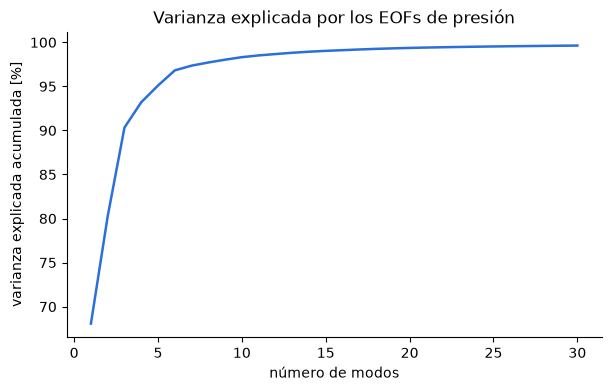

In [4]:
cum = np.cumsum(pca_msl.explained_variance_ratio)

fig, ax = plt.subplots(figsize=(6, 3.8), constrained_layout=True)
ax.plot(np.arange(1, N_PCS + 1), cum * 100, color='#2a6fdb', lw=1.8)
ax.set(xlabel='número de modos', ylabel='varianza explicada acumulada [%]', title='Varianza explicada por los EOFs de presión')
ax.spines[['top', 'right']].set_visible(False)
print(f'10 PCs: {cum[9] * 100:.1f} % | {N_PCS} PCs: {cum[-1] * 100:.1f} %')

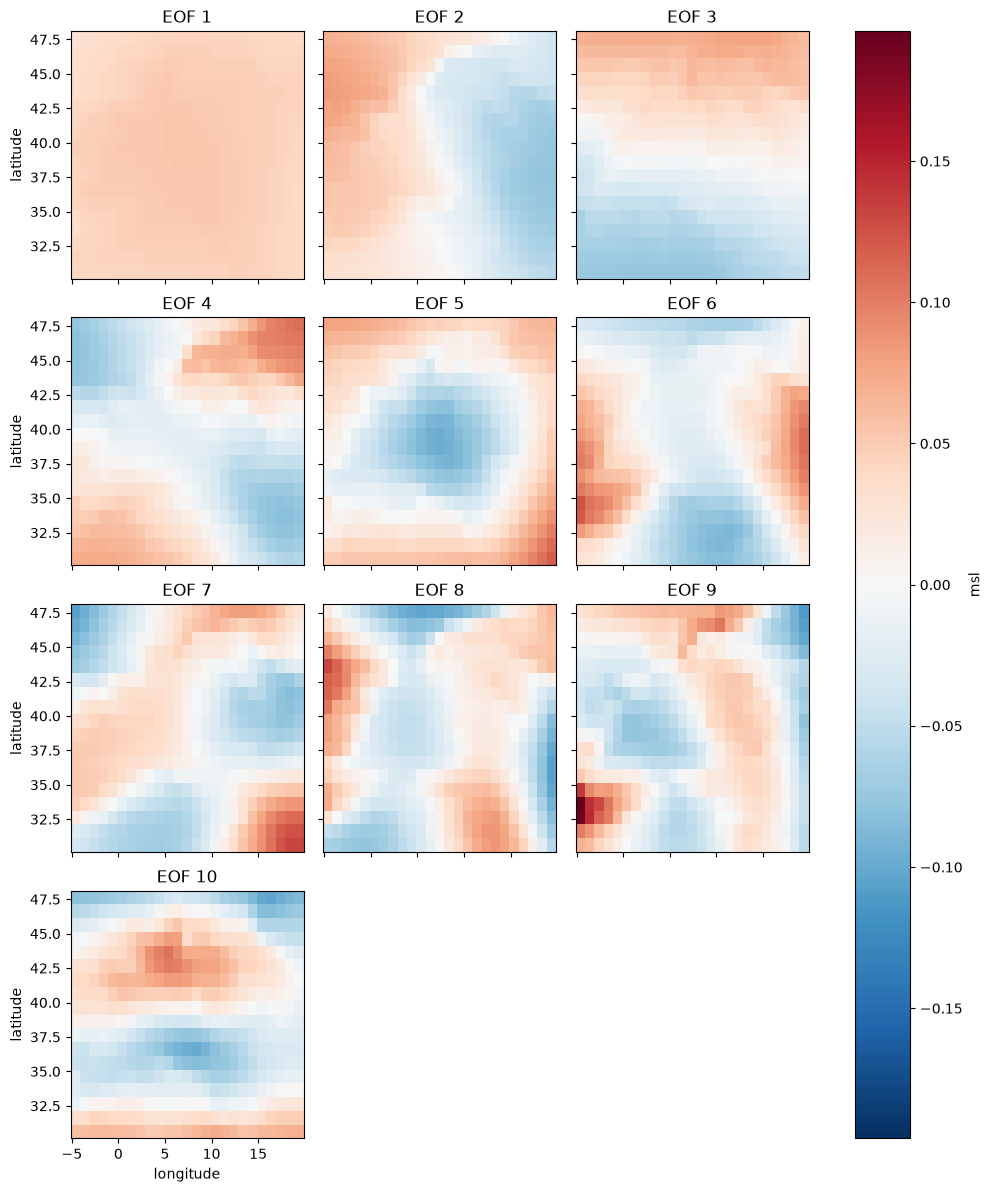

In [5]:
pca_msl.plot_eofs(vars_to_plot=['msl'], num_eofs=10)

#### PCs 1940–2026 y guardar

In [6]:
pcs = pca_msl.transform(data=era5[['msl']])
pcs_df = pd.DataFrame(pcs['PCs'].values, index=pd.DatetimeIndex(pcs['time'].values, name='time'),
                      columns=[f'msl_PC{i + 1}' for i in range(N_PCS)])

os.makedirs('outputs/pca', exist_ok=True)
pca_msl.save_model('outputs/pca/pca_msl.pkl')
pcs_df.to_csv('outputs/pca/pcs_msl_30_6h.csv', float_format='%.5f')
print(pcs_df.shape, pcs_df.index[0], pcs_df.index[-1])

2026-11-26 16:39:35,104 - PCA - WARNING - Using 450 out of 450 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method
2026-11-26 16:39:35,482 - PCA - WARNING - Attribute pcs is an xarray Dataset / Dataarray and will be pickled!


(126864, 30) 1940-01-01 00:00:00 2026-10-31 18:00:00


#### Comprobación: campo reconstruido con inverse_transform

In [7]:
t_check = slice('2000-01-01', '2000-12-31')
pcs_da = xr.DataArray(pcs_df.loc[t_check].values, dims=('time', 'n_component'),
                      coords={'time': pcs_df.loc[t_check].index, 'n_component': np.arange(N_PCS)})
rec = pca_msl.inverse_transform(pcs_da)['msl'].transpose('time', 'latitude', 'longitude')
obs = era5['msl'].sel(time=t_check).transpose('time', 'latitude', 'longitude')

print(f'R² campo (2000): {1 - float(((obs - rec) ** 2).sum() / ((obs - obs.mean("time")) ** 2).sum()):.3f}')

R² campo (2000): 0.997
